# SIS: Climate & City Size in Kazakhstan

**Author:** Mukhit | **Course project:** Data collection, preparation and EDA

## Research question
Is there a relationship between the climate of Kazakhstan's largest cities (mean temperature, precipitation, elevation) and their population?

## Data sources
| Source | Type | What we take |
|---|---|---|
| Wikipedia (list of cities in Kazakhstan) | Web scraping (`requests` + `BeautifulSoup`) | City names, population |
| Open-Meteo Geocoding API | API | Coordinates, elevation |
| Open-Meteo Historical Weather API | API | Daily mean temperature and precipitation for 2023 |

## Pipeline
1. Scrape the city table, then clean it
2. Collect coordinates and weather through the API, then clean it
3. Merge by city
4. Descriptive statistics and correlations
5. Visualizations (5 plots)
6. Conclusions

In [1]:
import sys
print(sys.executable)
!"{sys.executable}" -m pip install requests beautifulsoup4 pandas numpy matplotlib seaborn lxml

c:\Users\User\AppData\Local\Programs\Python\Python310\python.exe


[notice] A new release of pip available: 22.2.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# pip install requests beautifulsoup4 pandas matplotlib seaborn lxml
import re, time
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from urllib import robotparser

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

HEADERS = {"User-Agent": "KBTU-student-project/1.0 (educational; contact: student@kbtu.kz)"}
TOP_N = 15          # how many biggest cities to analyse
YEAR = 2023         # weather year

## 1. Web scraping: Wikipedia
First we check `robots.txt`, then download the page and parse the HTML table with BeautifulSoup.

In [3]:
# --- robots.txt check ---
rp = robotparser.RobotFileParser()
rp.set_url("https://en.wikipedia.org/robots.txt")
rp.read()

CANDIDATE_URLS = [
    "https://en.wikipedia.org/wiki/List_of_cities_and_towns_in_Kazakhstan",
    "https://en.wikipedia.org/wiki/List_of_cities_in_Kazakhstan",
    "https://en.wikipedia.org/wiki/List_of_largest_cities_of_Kazakhstan",
]
for u in CANDIDATE_URLS:
    print(u, "-> allowed by robots.txt:", rp.can_fetch(HEADERS["User-Agent"], u))

https://en.wikipedia.org/wiki/List_of_cities_and_towns_in_Kazakhstan -> allowed by robots.txt: False
https://en.wikipedia.org/wiki/List_of_cities_in_Kazakhstan -> allowed by robots.txt: False
https://en.wikipedia.org/wiki/List_of_largest_cities_of_Kazakhstan -> allowed by robots.txt: False


In [4]:
CANDIDATE_URLS = [
    "https://en.wikipedia.org/wiki/List_of_most_populous_cities_in_Kazakhstan",
]

def clean_text(t):
    return re.sub(r"\[.*?\]", "", t).replace("\xa0", " ").strip()

def parse_city_table(html):
    soup = BeautifulSoup(html, "html.parser")
    tables = soup.find_all("table", class_="wikitable")
    print("wikitables found:", len(tables))
    for table in tables:
        rows = table.find_all("tr")
        header = [clean_text(c.get_text(" ")) for c in rows[0].find_all(["th", "td"])]
        print("header:", header, "| rows:", len(rows))
        low = [h.lower() for h in header]
        name_idx = next((i for i, h in enumerate(low) if "city" in h or "name" in h), None)
        pop_idx = [i for i, h in enumerate(low) if "population" in h]
        if name_idx is None or not pop_idx or len(rows) < 5:
            continue
        pop_col = pop_idx[0]   # first population column = latest estimate
        data = []
        for r in rows[1:]:
            cells = [clean_text(c.get_text(" ")) for c in r.find_all(["th", "td"])]
            if len(cells) <= max(name_idx, pop_col):
                continue
            data.append({"City": cells[name_idx], "Population": cells[pop_col]})
        if data:
            print(f"Using column: '{header[pop_col]}'")
            return pd.DataFrame(data)
    return None

raw_cities = None
for url in CANDIDATE_URLS:
    print("robots.txt allows:", rp.can_fetch(HEADERS["User-Agent"], url))
    resp = requests.get(url, headers=HEADERS, timeout=30)
    print("HTTP status:", resp.status_code)
    if resp.status_code != 200:
        continue
    raw_cities = parse_city_table(resp.text)
    if raw_cities is not None:
        print("Scraped from:", url)
        break

assert raw_cities is not None, "No suitable table found, see the printed headers above"
print(raw_cities.shape)
raw_cities.head(10)

robots.txt allows: False
HTTP status: 200
wikitables found: 1
header: ['Rank', 'City or Settlement', 'Population (January 2023 estimate)', 'Population (October 2021 census)', 'Change', 'Region'] | rows: 88
Using column: 'Population (January 2023 estimate)'
Scraped from: https://en.wikipedia.org/wiki/List_of_most_populous_cities_in_Kazakhstan
(87, 2)


,City,Population
0,Almaty,"2,161,797"
1,Astana,"1,354,507"
2,Shymkent,"1,192,120"
3,Aktobe,"559,911"
4,Karaganda,"515,632"
5,Taraz,"427,356"
6,Oskemen,"352,894"
7,Pavlodar,"334,096"
8,Atyrau,"316,468"
9,Semey,"308,143"


### 1.1 Cleaning the scraped data
- rename columns to `snake_case`
- remove duplicates and empty rows
- convert `population` from text to integer
- handle missing values

In [5]:
cities = raw_cities.copy()
cities.columns = [c.strip().lower() for c in cities.columns]          # renaming

print("Before: ", cities.shape, "| duplicates:", cities.duplicated().sum())
cities = cities.drop_duplicates()
cities["city"] = cities["city"].str.replace(r"\(.*?\)", "", regex=True).str.strip()
cities = cities[cities["city"] != ""]
cities = cities.drop_duplicates(subset="city")

# text -> number: keep digits only
cities["population"] = (cities["population"].astype(str)
                        .str.replace(r"[^\d]", "", regex=True)
                        .replace("", np.nan)
                        .astype(float))

print("Missing values:\n", cities.isna().sum())
cities = cities.dropna(subset=["population"])
cities["population"] = cities["population"].astype(int)

cities = (cities.sort_values("population", ascending=False)
                .head(TOP_N).reset_index(drop=True))
print("After: ", cities.shape)
cities

Before:  (87, 2) | duplicates: 0
Missing values:
 city          0
population    0
dtype: int64
After:  (15, 2)


,city,population
0,Almaty,2161797
1,Astana,1354507
2,Shymkent,1192120
3,Aktobe,559911
4,Karaganda,515632
5,Taraz,427356
6,Oskemen,352894
7,Pavlodar,334096
8,Atyrau,316468
9,Semey,308143


## 2. API: Open-Meteo
1. **Geocoding API**: coordinates and elevation for each city
2. **Historical Weather API**: daily mean temperature and precipitation for 2023

In [6]:
GEO_URL = "https://geocoding-api.open-meteo.com/v1/search"

def geocode(city):
    r = requests.get(GEO_URL, params={"name": city, "count": 5, "country_code": "KZ", "language": "en"},
                     headers=HEADERS, timeout=30)
    r.raise_for_status()
    res = r.json().get("results")
    if not res:
        return None
    best = res[0]
    return {"city": city, "lat": best["latitude"], "lon": best["longitude"],
            "elevation_m": best.get("elevation")}

geo_rows = []
for c in cities["city"]:
    try:
        g = geocode(c)
    except Exception as e:
        print("Geocoding error for", c, e); g = None
    if g is None:
        print("Not found:", c)
    else:
        geo_rows.append(g)
    time.sleep(0.3)

geo = pd.DataFrame(geo_rows)
geo

,city,lat,lon,elevation_m
0,Almaty,43.25249,76.91150,783.0
1,Astana,51.18010,71.44598,358.0
2,Shymkent,42.30988,69.60042,520.0
3,Aktobe,50.27969,57.20718,210.0
4,Karaganda,49.80187,73.10211,545.0
5,Taraz,42.89799,71.37334,611.0
6,Oskemen,50.03660,82.49420,283.0
7,Pavlodar,52.27601,76.96881,125.0
8,Atyrau,47.10480,51.88427,-19.0
9,Semey,50.42064,80.25025,195.0


In [7]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

def get_weather(city, lat, lon, year=YEAR):
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
        "daily": "temperature_2m_mean,precipitation_sum",
        "timezone": "auto",
    }
    r = requests.get(ARCHIVE_URL, params=params, headers=HEADERS, timeout=60)
    r.raise_for_status()
    d = r.json()["daily"]
    df = pd.DataFrame(d)
    df["city"] = city
    return df

weather_frames = []
for _, row in geo.iterrows():
    try:
        weather_frames.append(get_weather(row["city"], row["lat"], row["lon"]))
        print("OK:", row["city"])
    except Exception as e:
        print("Weather error for", row["city"], e)
    time.sleep(1.0)       # be polite to the API

weather_raw = pd.concat(weather_frames, ignore_index=True)
print(weather_raw.shape)
weather_raw.head()

OK: Almaty
OK: Astana
OK: Shymkent
OK: Aktobe
OK: Karaganda
OK: Taraz
OK: Oskemen
OK: Pavlodar
OK: Atyrau
OK: Semey
OK: Kyzylorda
OK: Kostanay
OK: Aktau
OK: Oral
OK: Petropavl
(5475, 4)


,time,temperature_2m_mean,precipitation_sum,city
0,2023-01-01,-3.4,7.3,Almaty
1,2023-01-02,-3.7,0.0,Almaty
2,2023-01-03,-2.0,0.0,Almaty
3,2023-01-04,-0.8,13.7,Almaty
4,2023-01-05,1.1,0.0,Almaty


### 2.1 Cleaning the weather data

In [8]:
weather = weather_raw.rename(columns={"time": "date",
                                      "temperature_2m_mean": "temp_mean_c",
                                      "precipitation_sum": "precip_mm"})
weather["date"] = pd.to_datetime(weather["date"])
weather["month"] = weather["date"].dt.month

print("Missing values:\n", weather.isna().sum())
print("Duplicates:", weather.duplicated(subset=["city", "date"]).sum())

weather = weather.drop_duplicates(subset=["city", "date"])
# missing temperature: linear interpolation inside each city; missing precipitation: 0 mm
weather["temp_mean_c"] = weather.groupby("city")["temp_mean_c"].transform(lambda s: s.interpolate(limit_direction="both"))
weather["precip_mm"] = weather["precip_mm"].fillna(0)

weather.dtypes

Missing values:
 date           0
temp_mean_c    0
precip_mm      0
city           0
month          0
dtype: int64
Duplicates: 0


date           datetime64[ns]
temp_mean_c           float64
precip_mm             float64
city                   object
month                   int32
dtype: object

## 3. Merging
Daily weather is aggregated to **one row per city** (annual mean, summer/winter, total precipitation), then joined with population and geography on the `city` key.

In [9]:
climate = (weather.groupby("city")
    .agg(temp_mean_c=("temp_mean_c", "mean"),
         temp_min_c=("temp_mean_c", "min"),
         temp_max_c=("temp_mean_c", "max"),
         temp_std=("temp_mean_c", "std"),
         precip_total_mm=("precip_mm", "sum"),
         rainy_days=("precip_mm", lambda s: (s >= 1).sum()))
    .reset_index())

merged = (cities.merge(geo, on="city", how="inner")
                .merge(climate, on="city", how="inner"))
merged["temp_range_c"] = merged["temp_max_c"] - merged["temp_min_c"]
merged = merged.round(2)

print("Cities scraped:", len(cities), "| after merge:", len(merged))
merged

Cities scraped: 15 | after merge: 15


,city,population,lat,lon,elevation_m,temp_mean_c,temp_min_c,temp_max_c,temp_std,precip_total_mm,rainy_days,temp_range_c
0,Almaty,2161797,43.25,76.91,783.0,11.42,-22.4,31.8,11.43,562.5,86,54.2
1,Astana,1354507,51.18,71.45,358.0,5.72,-30.3,30.5,13.58,410.1,95,60.8
2,Shymkent,1192120,42.31,69.60,520.0,14.69,-21.4,34.0,11.09,513.6,74,55.4
3,Aktobe,559911,50.28,57.21,210.0,7.46,-34.0,33.9,13.60,580.1,95,67.9
4,Karaganda,515632,49.80,73.10,545.0,5.76,-30.9,29.5,13.14,481.5,95,60.4
5,Taraz,427356,42.90,71.37,611.0,12.32,-29.1,32.2,12.20,386.5,76,61.3
6,Oskemen,352894,50.04,82.49,283.0,6.10,-30.0,29.8,13.29,760.0,125,59.8
7,Pavlodar,334096,52.28,76.97,125.0,6.08,-28.5,31.5,13.82,394.0,90,60.0
8,Atyrau,316468,47.10,51.88,-19.0,12.66,-20.0,36.0,12.51,370.9,73,56.0
9,Semey,308143,50.42,80.25,195.0,6.64,-26.1,30.6,13.49,494.1,108,56.7


## 4. Exploratory Data Analysis

In [10]:
merged.describe().T

,count,mean,std,min,25%,50%,75%,max
population,15.0,587088.666667,553144.629267,222636.00,271552.000,334096.00,537771.500,2161797.00
lat,15.0,48.493333,4.128790,42.31,44.255,50.04,51.215,54.87
lon,15.0,67.474000,10.448343,51.17,60.415,69.60,75.005,82.49
elevation_m,15.0,272.800000,240.409234,-19.00,126.500,195.00,439.000,783.00
temp_mean_c,15.0,9.070667,3.653256,5.02,5.920,7.46,12.490,14.69
temp_min_c,15.0,-26.586667,6.379864,-35.90,-30.600,-28.50,-21.900,-12.80
temp_max_c,15.0,32.206667,2.117771,29.50,30.550,31.80,33.950,36.00
temp_std,15.0,12.713333,1.064765,10.24,12.355,13.14,13.520,13.82
precip_total_mm,15.0,461.180000,159.082298,110.60,390.250,481.50,543.200,760.00
rainy_days,15.0,84.533333,23.491234,30.00,75.000,90.00,95.000,125.00


In [11]:
num_cols = ["population", "lat", "elevation_m", "temp_mean_c", "temp_range_c",
            "precip_total_mm", "rainy_days"]
corr = merged[num_cols].corr()
corr.round(2)

,population,lat,elevation_m,temp_mean_c,temp_range_c,precip_total_mm,rainy_days
population,1.00,-0.40,0.74,0.18,-0.17,0.18,0.07
lat,-0.40,1.00,-0.44,-0.91,0.68,0.39,0.58
elevation_m,0.74,-0.44,1.00,0.09,0.03,0.28,0.17
temp_mean_c,0.18,-0.91,0.09,1.00,-0.71,-0.55,-0.76
temp_range_c,-0.17,0.68,0.03,-0.71,1.00,0.52,0.58
precip_total_mm,0.18,0.39,0.28,-0.55,0.52,1.00,0.88
rainy_days,0.07,0.58,0.17,-0.76,0.58,0.88,1.00


In [12]:
# strongest correlations with population
print(corr["population"].drop("population").sort_values(key=abs, ascending=False).round(2))

print("\nWarmest city:", merged.loc[merged.temp_mean_c.idxmax(), "city"])
print("Coldest city:", merged.loc[merged.temp_mean_c.idxmin(), "city"])
print("Wettest city:", merged.loc[merged.precip_total_mm.idxmax(), "city"])
print("Driest city: ", merged.loc[merged.precip_total_mm.idxmin(), "city"])

elevation_m        0.74
lat               -0.40
precip_total_mm    0.18
temp_mean_c        0.18
temp_range_c      -0.17
rainy_days         0.07
Name: population, dtype: float64

Warmest city: Shymkent
Coldest city: Petropavl
Wettest city: Oskemen
Driest city:  Kyzylorda


## 5. Visualizations

C:\Users\User\AppData\Local\Temp\ipykernel_11672\1239946661.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=d, x="temp_mean_c", y="city", palette="coolwarm", ax=ax)


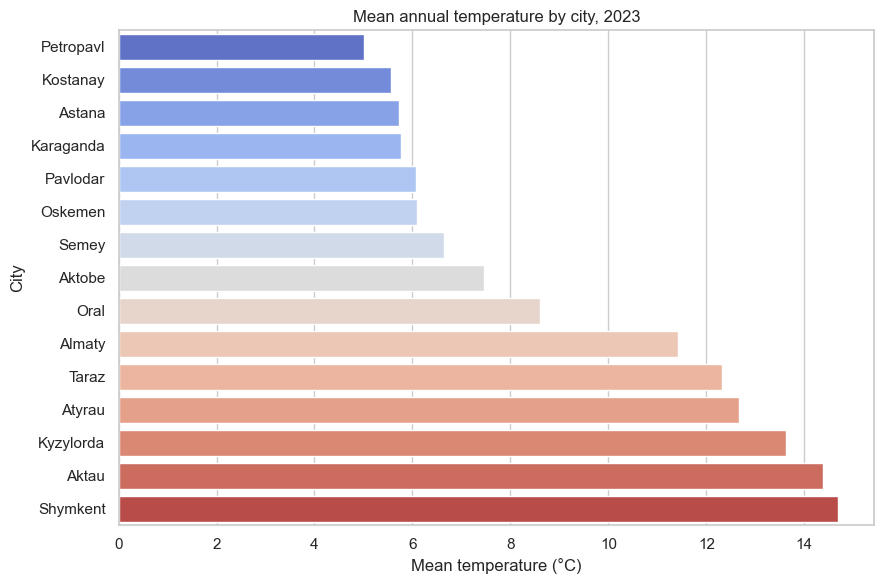

In [13]:
# Plot 1: mean annual temperature by city
d = merged.sort_values("temp_mean_c")
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=d, x="temp_mean_c", y="city", palette="coolwarm", ax=ax)
ax.set_title(f"Mean annual temperature by city, {YEAR}")
ax.set_xlabel("Mean temperature (°C)")
ax.set_ylabel("City")
plt.tight_layout(); plt.show()

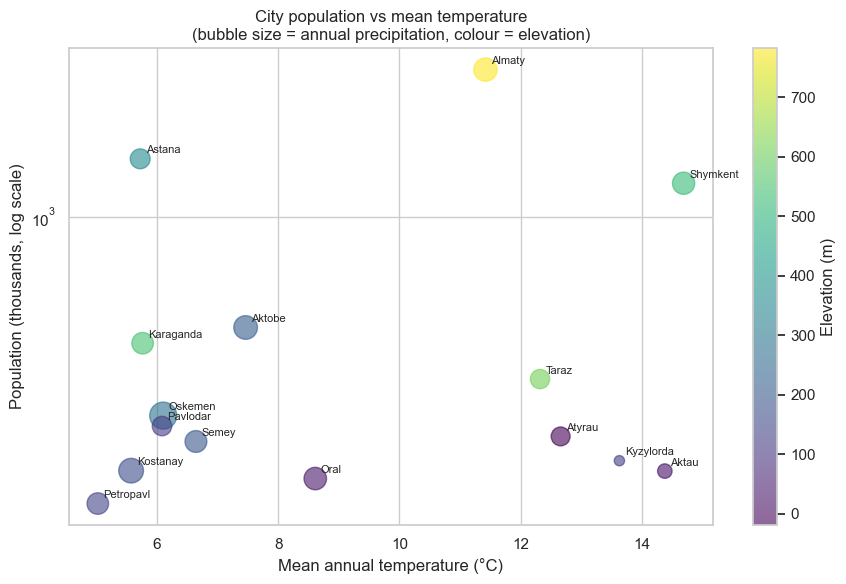

In [14]:
# Plot 2: population vs mean temperature (bubble = precipitation)
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(merged["temp_mean_c"], merged["population"] / 1e3,
                s=merged["precip_total_mm"] / 2, alpha=0.6, c=merged["elevation_m"], cmap="viridis")
for _, r in merged.iterrows():
    ax.annotate(r["city"], (r["temp_mean_c"], r["population"] / 1e3), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_yscale("log")
ax.set_title("City population vs mean temperature\n(bubble size = annual precipitation, colour = elevation)")
ax.set_xlabel("Mean annual temperature (°C)")
ax.set_ylabel("Population (thousands, log scale)")
plt.colorbar(sc, label="Elevation (m)")
plt.tight_layout(); plt.show()

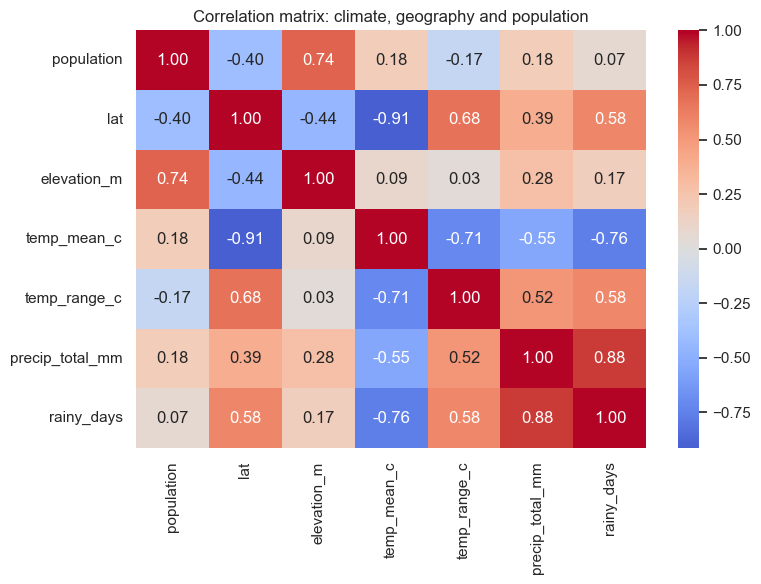

In [15]:
# Plot 3: correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix: climate, geography and population")
plt.tight_layout(); plt.show()

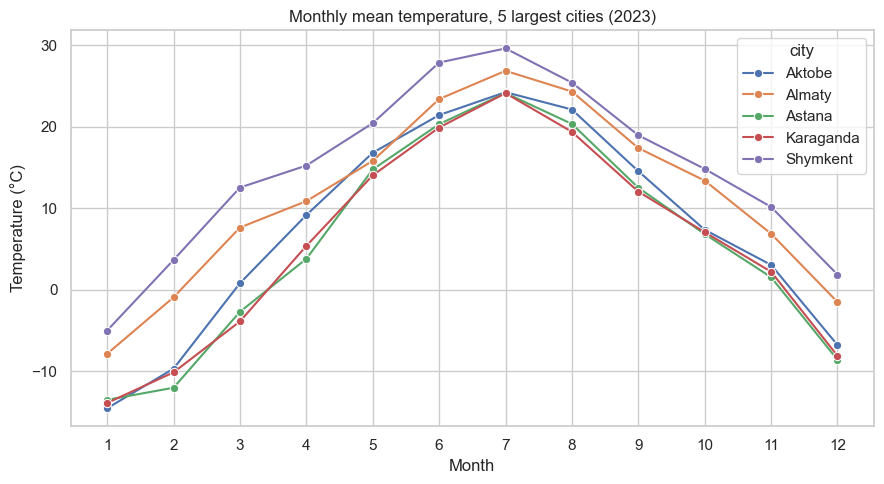

In [16]:
# Plot 4: monthly temperature profile for the 5 biggest cities
top5 = merged.nlargest(5, "population")["city"]
monthly = (weather[weather["city"].isin(top5)]
           .groupby(["city", "month"])["temp_mean_c"].mean().reset_index())
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=monthly, x="month", y="temp_mean_c", hue="city", marker="o", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_title(f"Monthly mean temperature, 5 largest cities ({YEAR})")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
plt.tight_layout(); plt.show()

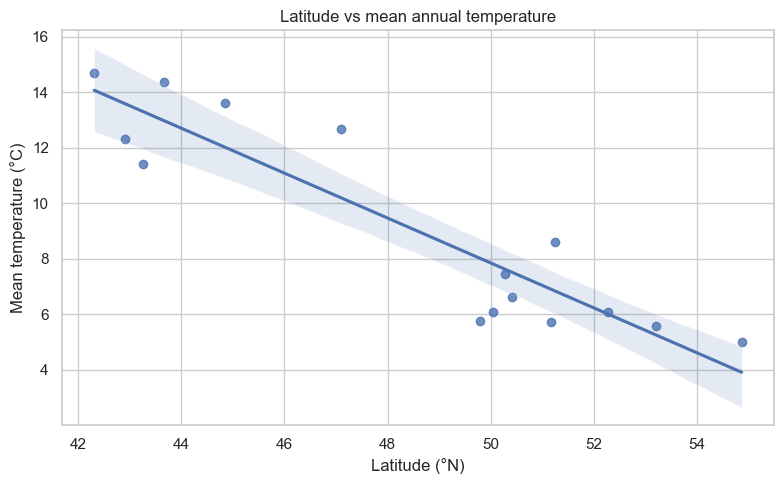

In [17]:
# Plot 5: latitude vs temperature, with regression line
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=merged, x="lat", y="temp_mean_c", ax=ax)
ax.set_title("Latitude vs mean annual temperature")
ax.set_xlabel("Latitude (°N)")
ax.set_ylabel("Mean temperature (°C)")
plt.tight_layout(); plt.show()

## 6. Conclusions
*(Run all cells first, then check these statements against your own numbers and edit them.)*

- **Approach:** population was scraped from Wikipedia, weather and geography came from Open-Meteo. The datasets were cleaned (types, duplicates, missing values, column names) and merged on `city`.
- **Climate pattern:** the cities show a strong continental climate. The temperature range between the coldest and warmest day in a year is large, and temperature clearly falls with latitude (plot 5).
- **Population vs climate:** see the correlation matrix (plot 3). Look at the sign and size of the correlation of `population` with `temp_mean_c`, `elevation_m` and `precip_total_mm`.
- **Limitations:** only ~15 cities, so correlations are unstable. One year of weather is not climate. Population is a snapshot, and large cities (Almaty, Astana) are driven by economics and politics, not weather.
- **Next steps:** add more years of weather data and more cities, and add GDP or region as another variable.